In [1]:
import os
import warnings

import ccxt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox

from sklearn.base import clone
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.multioutput import MultiOutputRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from lightgbm import LGBMRegressor

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

EXCHANGE_ID = "binance"
SYMBOLS = {
    "BNB": "BNB/USDT",
    "XRP": "XRP/USDT",
    "ADA": "ADA/USDT",
}
ASSETS = list(SYMBOLS)
INTERVAL = "1h"
START = "2024-10-01"
END = "2026-10-01"
DATA_CACHE = "ccxt_binance_1h_close.csv"
CANDLES_PER_REQUEST = 1000

TEST_SIZE = 0.15
N_LAGS = 5
WINDOWS = (5, 10, 20)

SEED = 42
LGBM_PARAMS = dict(
    n_estimators=300,
    learning_rate=0.03,
    num_leaves=15,
    min_child_samples=100,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_lambda=5.0,
    random_state=SEED,
    verbose=-1,
)

In [2]:
if os.path.exists(DATA_CACHE):
    prices = pd.read_csv(DATA_CACHE, index_col=0)
else:
    exchange = getattr(ccxt, EXCHANGE_ID)({"enableRateLimit": True})
    exchange.load_markets()

    timeframe_ms = exchange.parse_timeframe(INTERVAL) * 1000
    start_ms = exchange.parse8601(f"{START}T00:00:00Z")
    end_ms = exchange.parse8601(f"{END}T00:00:00Z")

    close_by_asset = {}
    for asset, symbol in SYMBOLS.items():
        close_rows = []
        since = start_ms

        while since < end_ms:
            candles = exchange.fetch_ohlcv(symbol, INTERVAL, since=since, limit=CANDLES_PER_REQUEST)

            if not candles:
                break

            for candle in candles:
                close_rows.append((candle[0], float(candle[4])))

            since = candles[-1][0] + timeframe_ms

        asset_df = pd.DataFrame(close_rows, columns=["timestamp", "close"])
        asset_df = asset_df[asset_df["timestamp"] < end_ms]
        asset_df.index = pd.to_datetime(asset_df.pop("timestamp"), unit="ms", utc=True)
        close = asset_df["close"]
        close_by_asset[asset] = close[~close.index.duplicated()]

    prices = pd.concat(close_by_asset, axis=1).dropna()
    prices.to_csv(DATA_CACHE)

prices.index = pd.to_datetime(prices.index, utc=True)
prices = prices[ASSETS].sort_index()

prices.head()

,BNB,XRP,ADA
timestamp,,,
2024-10-01 00:00:00+00:00,571.9,0.6202,0.3774
2024-10-01 01:00:00+00:00,573.5,0.6218,0.3778
2024-10-01 02:00:00+00:00,573.6,0.6225,0.3787
2024-10-01 03:00:00+00:00,576.9,0.6231,0.3820
2024-10-01 04:00:00+00:00,581.4,0.6194,0.3826


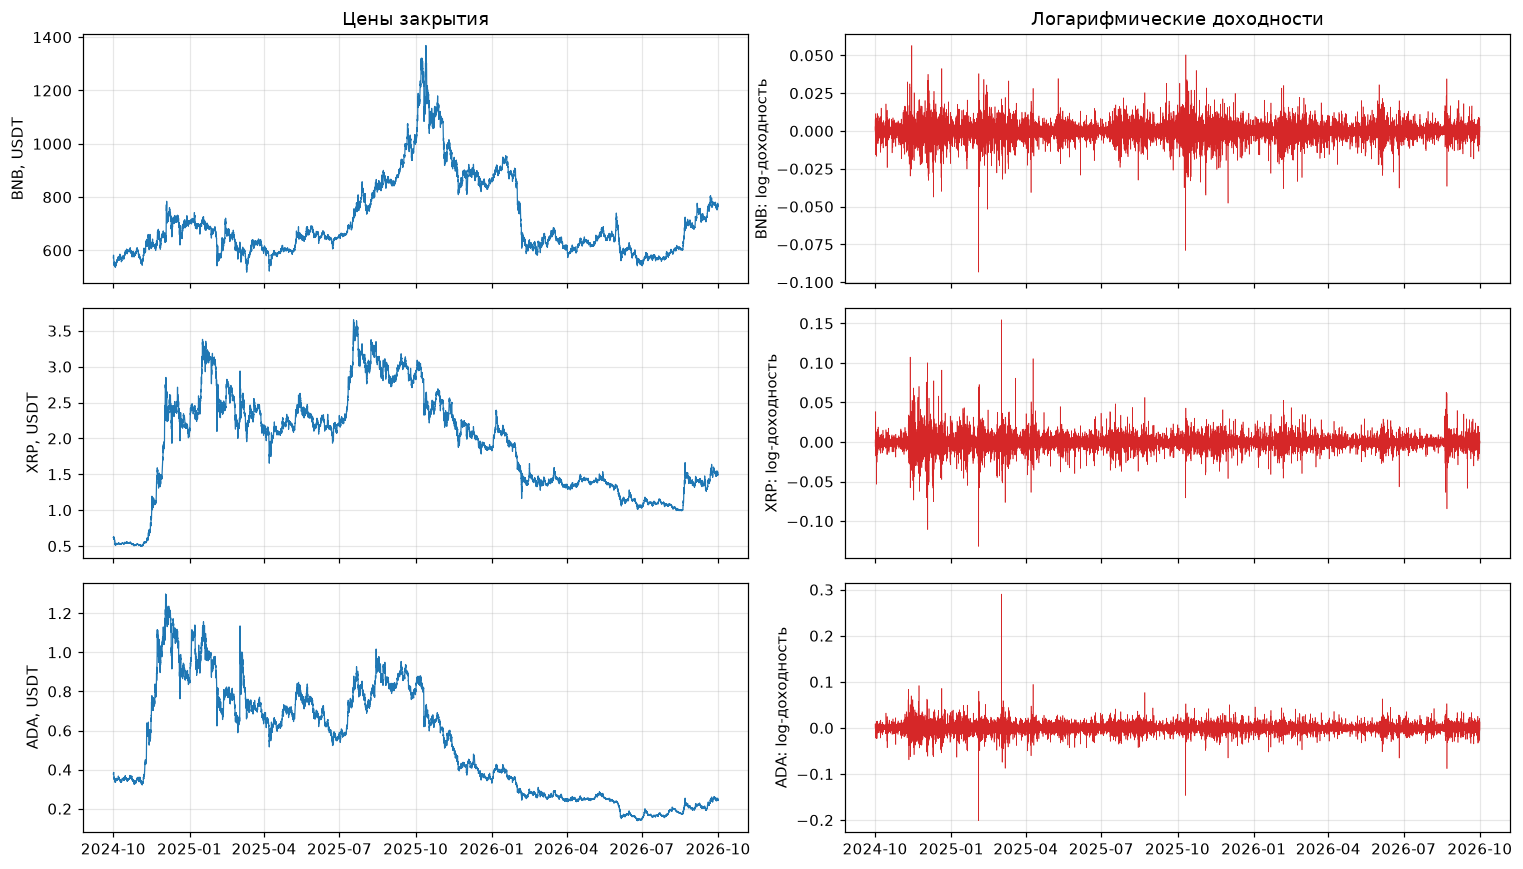

,mean,std,min,max,skew,excess kurtosis
BNB,0.00002,0.00555,-0.09334,0.05652,-0.70219,14.94858
XRP,0.00005,0.00903,-0.13205,0.15455,0.36892,22.90683
ADA,-0.00002,0.01019,-0.20135,0.29050,1.04227,61.07388


Корреляции доходностей:


,BNB,XRP,ADA
BNB,1.000,0.649,0.684
XRP,0.649,1.000,0.802
ADA,0.684,0.802,1.000


In [3]:
returns = np.log(prices).diff().dropna()

fig, axes = plt.subplots(3, 2, figsize=(14, 8), sharex="col")
for row, asset in enumerate(ASSETS):
    axes[row, 0].plot(prices.index, prices[asset], lw=0.8)
    axes[row, 0].set_ylabel(f"{asset}, USDT")
    axes[row, 1].plot(returns.index, returns[asset], lw=0.4, color="tab:red")
    axes[row, 1].set_ylabel(f"{asset}: log-доходность")
axes[0, 0].set_title("Цены закрытия")
axes[0, 1].set_title("Логарифмические доходности")
plt.tight_layout()
plt.show()

stats = returns.describe().T[["mean", "std", "min", "max"]]
stats["skew"] = returns.skew()
stats["excess kurtosis"] = returns.kurt()

display(stats.round(5))
print("Корреляции доходностей:")
display(returns.corr().round(3))

In [4]:
series_to_test = {
    "ln(цены)": np.log(prices),
    "Логарифмические доходности": returns,
}

for title, frame in series_to_test.items():
    adf_rows = []
    for asset in frame.columns:
        adf_stat, p_value, n_lags_used, _, critical_values, _ = adfuller(frame[asset].dropna(), autolag="AIC")
        adf_rows.append({
            "ряд": asset,
            "ADF-статистика": adf_stat,
            "p-value": p_value,
            "лагов": n_lags_used,
            "крит. 5%": critical_values["5%"],
            "стационарен (α=5%)": p_value < 0.05,
        })
    print(f"{title}:")
    display(pd.DataFrame(adf_rows).set_index("ряд").round(4))

ln(цены):


,ADF-статистика,p-value,лагов,крит. 5%,стационарен (α=5%)
ряд,,,,,
BNB,-2.0135,0.2807,4,-2.8617,False
XRP,-2.3977,0.1424,25,-2.8617,False
ADA,-0.8779,0.7952,24,-2.8617,False


Логарифмические доходности:


,ADF-статистика,p-value,лагов,крит. 5%,стационарен (α=5%)
ряд,,,,,
BNB,-66.4043,0.0,3,-2.8617,True
XRP,-26.7458,0.0,24,-2.8617,True
ADA,-28.4350,0.0,23,-2.8617,True


In [5]:
feature_columns = {}
for asset in returns.columns:
    asset_returns = returns[asset]

    for lag in range(1, N_LAGS + 1):
        feature_columns[f"{asset}_lag{lag}"] = asset_returns.shift(lag)

    for window in WINDOWS:
        feature_columns[f"{asset}_rstd{window}"] = asset_returns.rolling(window).std().shift(1)
        feature_columns[f"{asset}_rmaabs{window}"] = asset_returns.abs().rolling(window).mean().shift(1)

features_raw = pd.DataFrame(feature_columns, index=returns.index)

dataset = pd.concat([features_raw, returns.add_prefix("y_")], axis=1).dropna()

X = dataset[features_raw.columns]
Y = dataset[["y_" + asset for asset in ASSETS]].copy()
Y.columns = ASSETS

n_train = int(len(X) * (1 - TEST_SIZE))
X_train, X_test = X.iloc[:n_train], X.iloc[n_train:]
Y_train, Y_test = Y.iloc[:n_train], Y.iloc[n_train:]


In [6]:
ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge()),
])
ridge_search = GridSearchCV(
    MultiOutputRegressor(ridge_pipeline),
    param_grid={"estimator__ridge__alpha": [1, 10, 100, 1e3, 3e3, 1e4, 3e4, 1e5]},
    cv=TimeSeriesSplit(n_splits=5),
    scoring="neg_root_mean_squared_error",
)
ridge_search.fit(X_train, Y_train)
print("Лучший alpha для Ridge:", ridge_search.best_params_["estimator__ridge__alpha"])

mean_models = {
    "Ridge": ridge_search.best_estimator_,
    "LightGBM": MultiOutputRegressor(LGBMRegressor(**LGBM_PARAMS)),
}
for model in mean_models.values():
    model.fit(X_train, Y_train)

Лучший alpha для Ridge: 100000.0


In [7]:
mean_pred_by_model = {}
for model_name, model in mean_models.items():
    mean_pred_by_model[model_name] = pd.DataFrame(model.predict(X_test), index=X_test.index, columns=ASSETS)
# mean_pred_by_model["Нулевой прогноз"] = pd.DataFrame(0.0, index=X_test.index, columns=ASSETS)

metrics_by_model = {}
for model_name, y_pred in mean_pred_by_model.items():
    mae = mean_absolute_error(Y_test, y_pred, multioutput="raw_values")
    rmse = np.sqrt(mean_squared_error(Y_test, y_pred, multioutput="raw_values"))
    metrics_by_model[model_name] = pd.DataFrame({"MAE": mae, "RMSE": rmse}, index=ASSETS)
mean_metrics = pd.concat(metrics_by_model, names=["модель", "актив"])

# zero_rmse = mean_metrics.loc["Нулевой прогноз", "RMSE"]
# mean_metrics["RMSE к нулевому прогнозу, %"] = [
#     100 * (mean_metrics.loc[(model_name, asset), "RMSE"] / zero_rmse[asset] - 1)
#     for model_name, asset in mean_metrics.index
# ]

display(mean_metrics.round(3))

MAE   RMSE
модель   актив              
Ridge    BNB    0.003  0.004
         XRP    0.004  0.007
         ADA    0.006  0.008
LightGBM BNB    0.003  0.004
         XRP    0.004  0.007
         ADA    0.006  0.008

In [8]:
cv_models = dict(mean_models)


cv_rmse = {}

for model_name, model in cv_models.items():
    fold_rmse = []

    for fit_idx, val_idx in TimeSeriesSplit(n_splits=5).split(X_train):

        fitted = clone(model).fit(
            X_train.iloc[fit_idx],
            Y_train.iloc[fit_idx]
        )

        y_pred = fitted.predict(X_train.iloc[val_idx])
        y_true = Y_train.iloc[val_idx].values


        fold_rmse.append(
            np.sqrt(((y_true - y_pred) ** 2).mean(axis=0))
        )

    cv_rmse[model_name] = pd.Series(
        np.mean(fold_rmse, axis=0),
        index=ASSETS
    )

cv_rmse = pd.DataFrame(cv_rmse)

print("CV-RMSE на Train (TimeSeriesSplit):")
display(cv_rmse.round(6))

target_std = Y_train.std()
relative_rmse = cv_rmse.div(target_std, axis=0)

best_mean_name = relative_rmse.mean().idxmin()

print("Модель средних для 2-го шага (волатильность):", best_mean_name)

mean_pred_all = pd.DataFrame(
    mean_models[best_mean_name].predict(X),
    index=X.index,
    columns=ASSETS
)

residuals = Y - mean_pred_all


CV-RMSE на Train (TimeSeriesSplit):


,Ridge,LightGBM
BNB,0.005505,0.005602
XRP,0.008010,0.008151
ADA,0.009547,0.009712


Модель средних для 2-го шага (волатильность): Ridge


In [9]:
lb_lags = [10, 24]
ljung_box_train = pd.DataFrame(
    {asset: acorr_ljungbox(residuals[asset].iloc[:n_train] ** 2, lags=lb_lags)["lb_pvalue"].values
     for asset in ASSETS},
    index=[f"lag {lag}" for lag in lb_lags],
)

print("p-value Ljung–Box для e² (малые значения ⇒ кластеризация волатильности ⇒ нужен 2-й шаг):")
display(ljung_box_train.round(4))

p-value Ljung–Box для e² (малые значения ⇒ кластеризация волатильности ⇒ нужен 2-й шаг):


,BNB,XRP,ADA
lag 10,0.0,0.0,0.0
lag 24,0.0,0.0,0.0


In [10]:
VOL_WINDOWS = (5, 10, 20, 60)

residuals_sq = residuals ** 2

vol_feature_columns = {}
for asset in residuals.columns:

    for lag in range(1, N_LAGS + 1):
        vol_feature_columns[f"{asset}_e2_lag{lag}"] = residuals_sq[asset].shift(lag)

    for window in VOL_WINDOWS:
        vol_feature_columns[f"{asset}_e2_ma{window}"] = residuals_sq[asset].rolling(window).mean().shift(1)
vol_features = pd.DataFrame(vol_feature_columns, index=residuals.index)

hour = residuals.index.hour
vol_features["hour_sin"] = np.sin(2 * np.pi * hour / 24)
vol_features["hour_cos"] = np.cos(2 * np.pi * hour / 24)

first_step_vol_cols = [col for col in X.columns if ("_rstd" in col) or ("_rmaabs" in col)]
vol_features = pd.concat([vol_features, X[first_step_vol_cols]], axis=1).dropna()

train_index = vol_features.index.intersection(X_train.index)
test_index = X_test.index

vol_X_train, vol_X_test = vol_features.loc[train_index], vol_features.loc[test_index]
resid_sq_train, resid_sq_test = residuals_sq.loc[train_index], residuals_sq.loc[test_index]


In [11]:
EPS_LOG = 1e-10
LOG_MODEL = "LGBM ln e² (exp)"

var_forecast = {
    LOG_MODEL: pd.DataFrame(
        index=test_index,
        columns=ASSETS,
        dtype=float
    )
}

for asset in ASSETS:

    y_train = resid_sq_train[asset]

    y_train_log = np.log(y_train + EPS_LOG)


    model_log = LGBMRegressor(
        **LGBM_PARAMS
    ).fit(vol_X_train, y_train_log)

    train_residuals = (
        y_train_log - model_log.predict(vol_X_train)
    )
    smearing = np.mean(np.exp(train_residuals))

    forecast = (
        np.exp(model_log.predict(vol_X_test)) * smearing
    )

    var_forecast[LOG_MODEL][asset] = forecast

In [12]:
forecast = var_forecast[LOG_MODEL]

qlike_by_asset = {}

for asset in ASSETS:
    h = np.asarray(forecast[asset], dtype=float)
    e2 = np.asarray(resid_sq_test[asset], dtype=float)

    h = np.maximum(h, EPS_LOG)

    qlike_by_asset[asset] = np.mean(
        np.log(h) + e2 / h
    )

qlike_table = pd.DataFrame({
    "QLIKE": qlike_by_asset
})

display(qlike_table.round(4))

best_vol_name = LOG_MODEL
best_var_forecast = var_forecast[LOG_MODEL]
sigma = np.sqrt(best_var_forecast)

print("Модель волатильности:", best_vol_name)

,QLIKE
BNB,-10.3018
XRP,-9.4539
ADA,-8.7204


Модель волатильности: LGBM ln e² (exp)


In [13]:
mean_pred_test = mean_pred_all.loc[test_index]
forecast_error = Y_test - mean_pred_test
standardized_resid = forecast_error / sigma

inside_interval = forecast_error.abs() <= 1.96 * sigma
coverage = inside_interval.mean()
print("Доля наблюдений внутри ±1.96σ̂ (номинал 95 %):")
display(coverage.round(3).to_frame("покрытие").T)

# lb_lags = [10, 24]
# lb_index = [f"lag {lag}" for lag in lb_lags]
# ljung_box_e2 = pd.DataFrame(
#     {asset: acorr_ljungbox(resid_sq_test[asset], lags=lb_lags)["lb_pvalue"].values for asset in ASSETS},
#     index=lb_index)
# ljung_box_z2 = pd.DataFrame(
#     {asset: acorr_ljungbox(standardized_resid[asset] ** 2, lags=lb_lags)["lb_pvalue"].values for asset in ASSETS},
#     index=lb_index)
#
# print("Ljung–Box p-value для e² (до стандартизации, Test):")
# display(ljung_box_e2.round(4))
# print("Ljung–Box p-value для z² = (e/σ̂)² (после стандартизации, Test):")
# display(ljung_box_z2.round(4))

Доля наблюдений внутри ±1.96σ̂ (номинал 95 %):


,BNB,XRP,ADA
покрытие,0.94,0.942,0.94


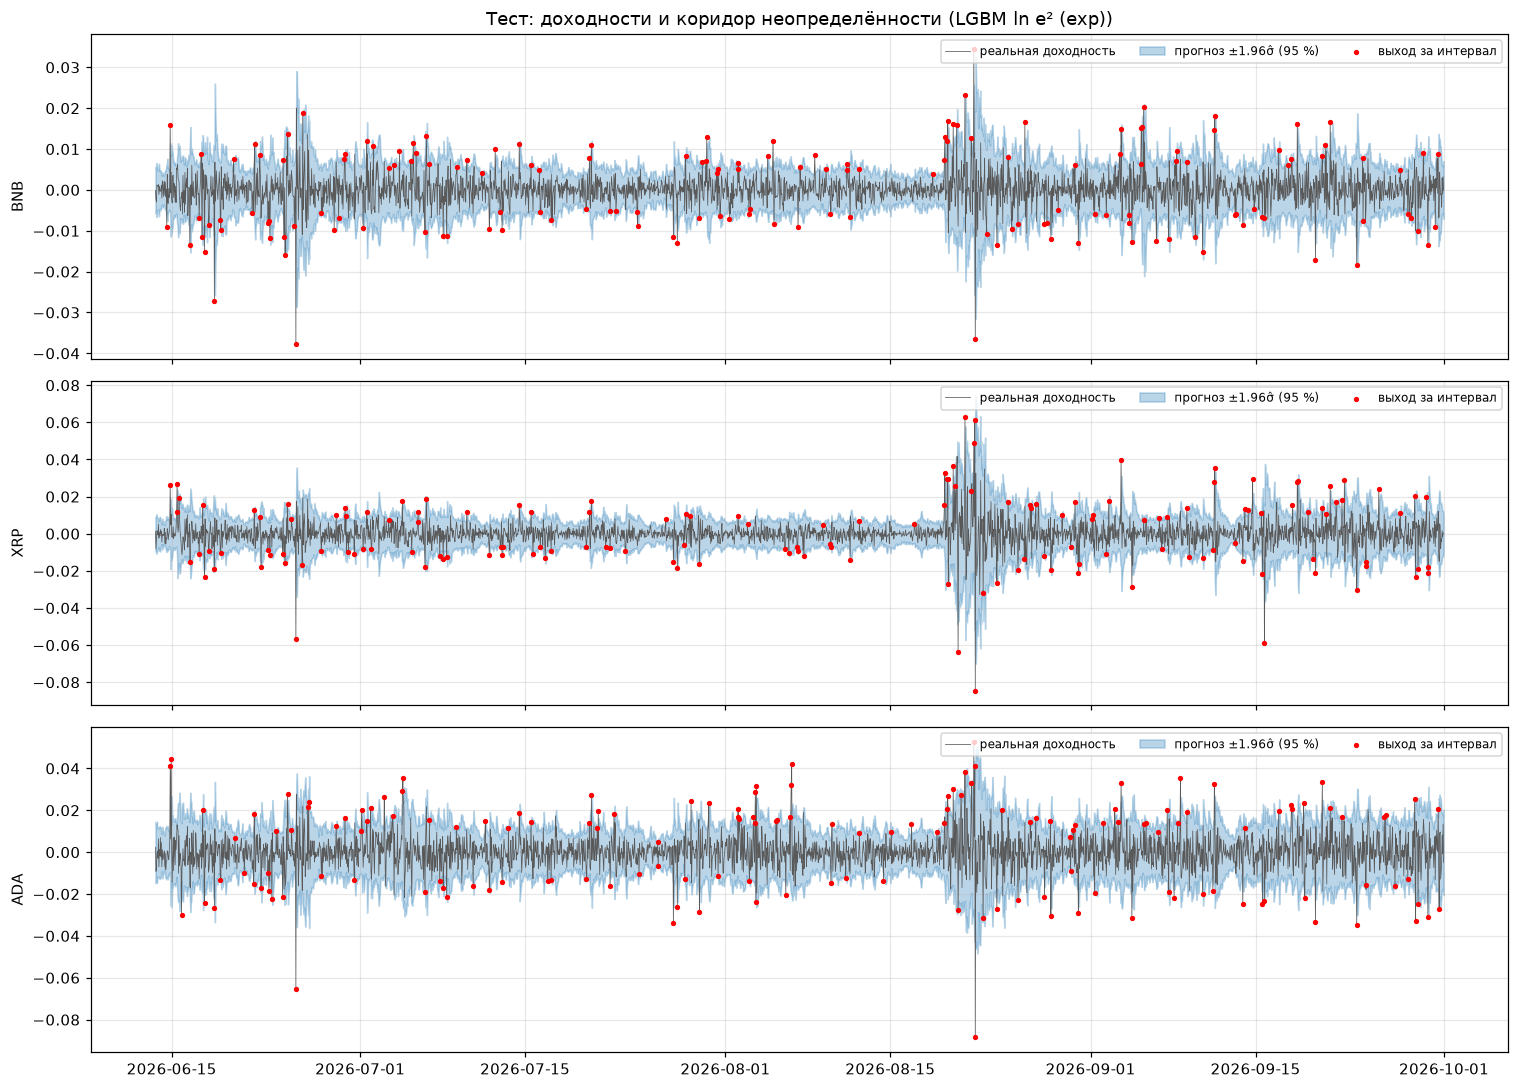

In [14]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
for ax, asset in zip(axes, ASSETS):
    actual = Y_test[asset]
    lower = mean_pred_test[asset] - 1.96 * sigma[asset]
    upper = mean_pred_test[asset] + 1.96 * sigma[asset]
    outside = (actual < lower) | (actual > upper)             # точки вне интервала

    ax.plot(actual.index, actual, lw=0.5, color="0.35", label="реальная доходность")
    ax.fill_between(actual.index, lower, upper, color="tab:blue", alpha=0.3, label="прогноз ±1.96σ̂ (95 %)")
    ax.scatter(actual.index[outside], actual[outside], s=6, color="red", zorder=3, label="выход за интервал")
    ax.set_ylabel(asset)
    ax.legend(loc="upper right", ncol=3, fontsize=8)

axes[0].set_title(f"Тест: доходности и коридор неопределённости ({best_vol_name})")
plt.tight_layout()
plt.show()

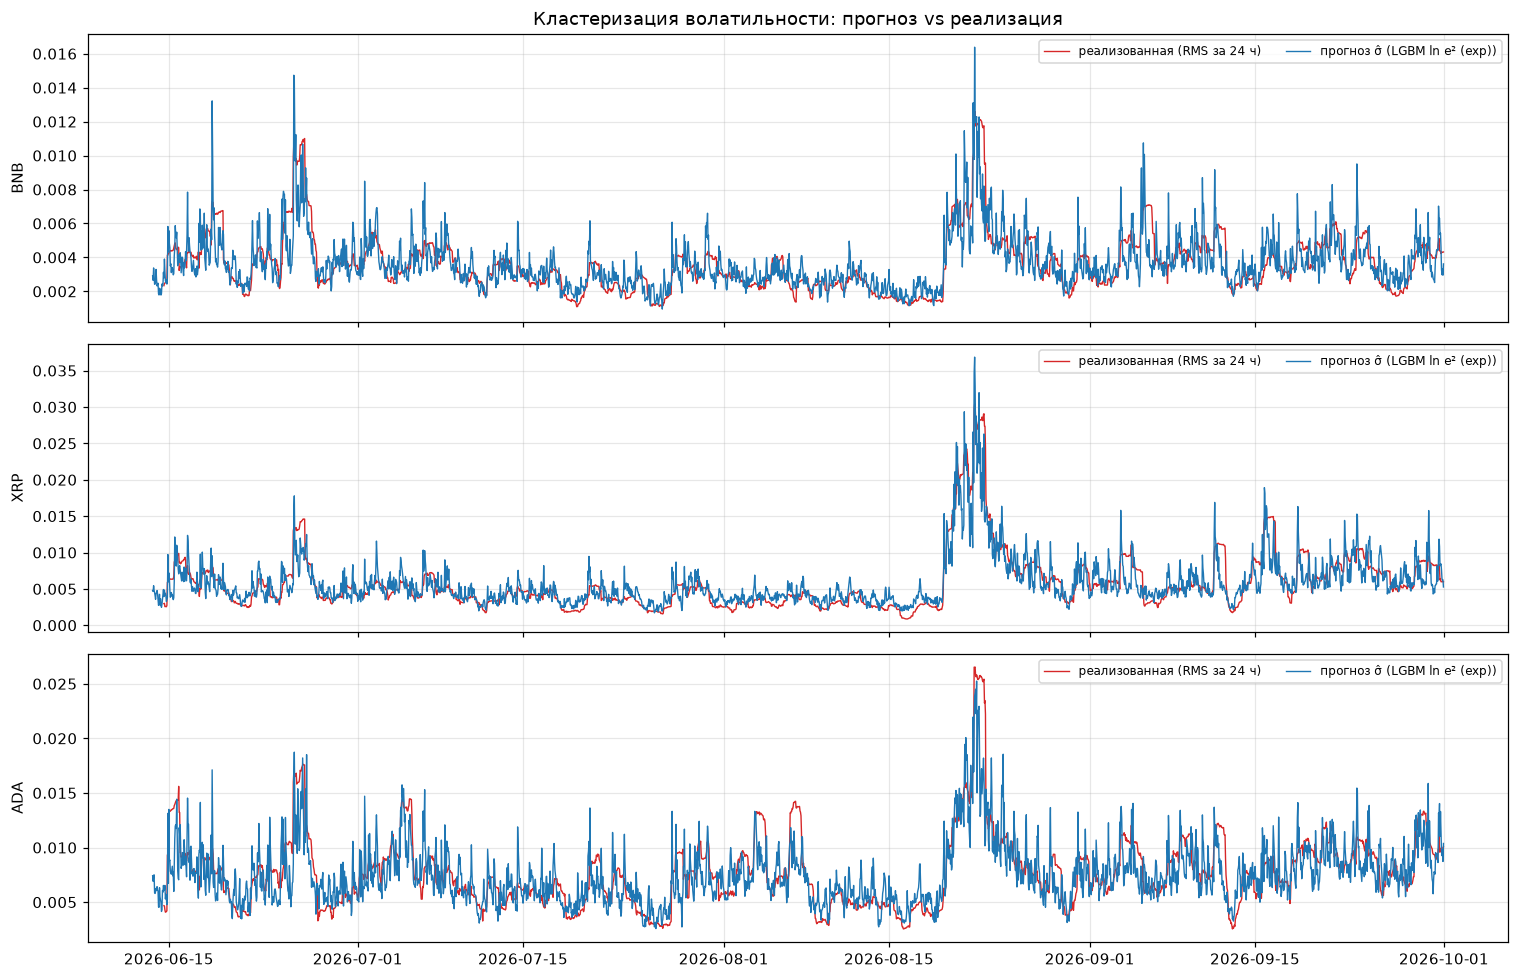

,BNB,XRP,ADA
corr,0.191,0.375,0.236


In [15]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
for ax, asset in zip(axes, ASSETS):
    realized_vol = np.sqrt(residuals_sq.loc[test_index, asset].rolling(24).mean())

    ax.plot(test_index, realized_vol, lw=0.9, color="tab:red", label="реализованная (RMS за 24 ч)")
    ax.plot(test_index, sigma[asset], lw=0.9, color="tab:blue", label=f"прогноз σ̂ ({best_vol_name})")
    ax.set_ylabel(asset)
    ax.legend(loc="upper right", ncol=2, fontsize=8)

axes[0].set_title("Кластеризация волатильности: прогноз vs реализация")
plt.tight_layout()
plt.show()

corr_with_realized = {
    asset: np.corrcoef(best_var_forecast[asset], resid_sq_test[asset])[0, 1] for asset in ASSETS}

display(pd.Series(corr_with_realized).round(3).to_frame("corr").T)

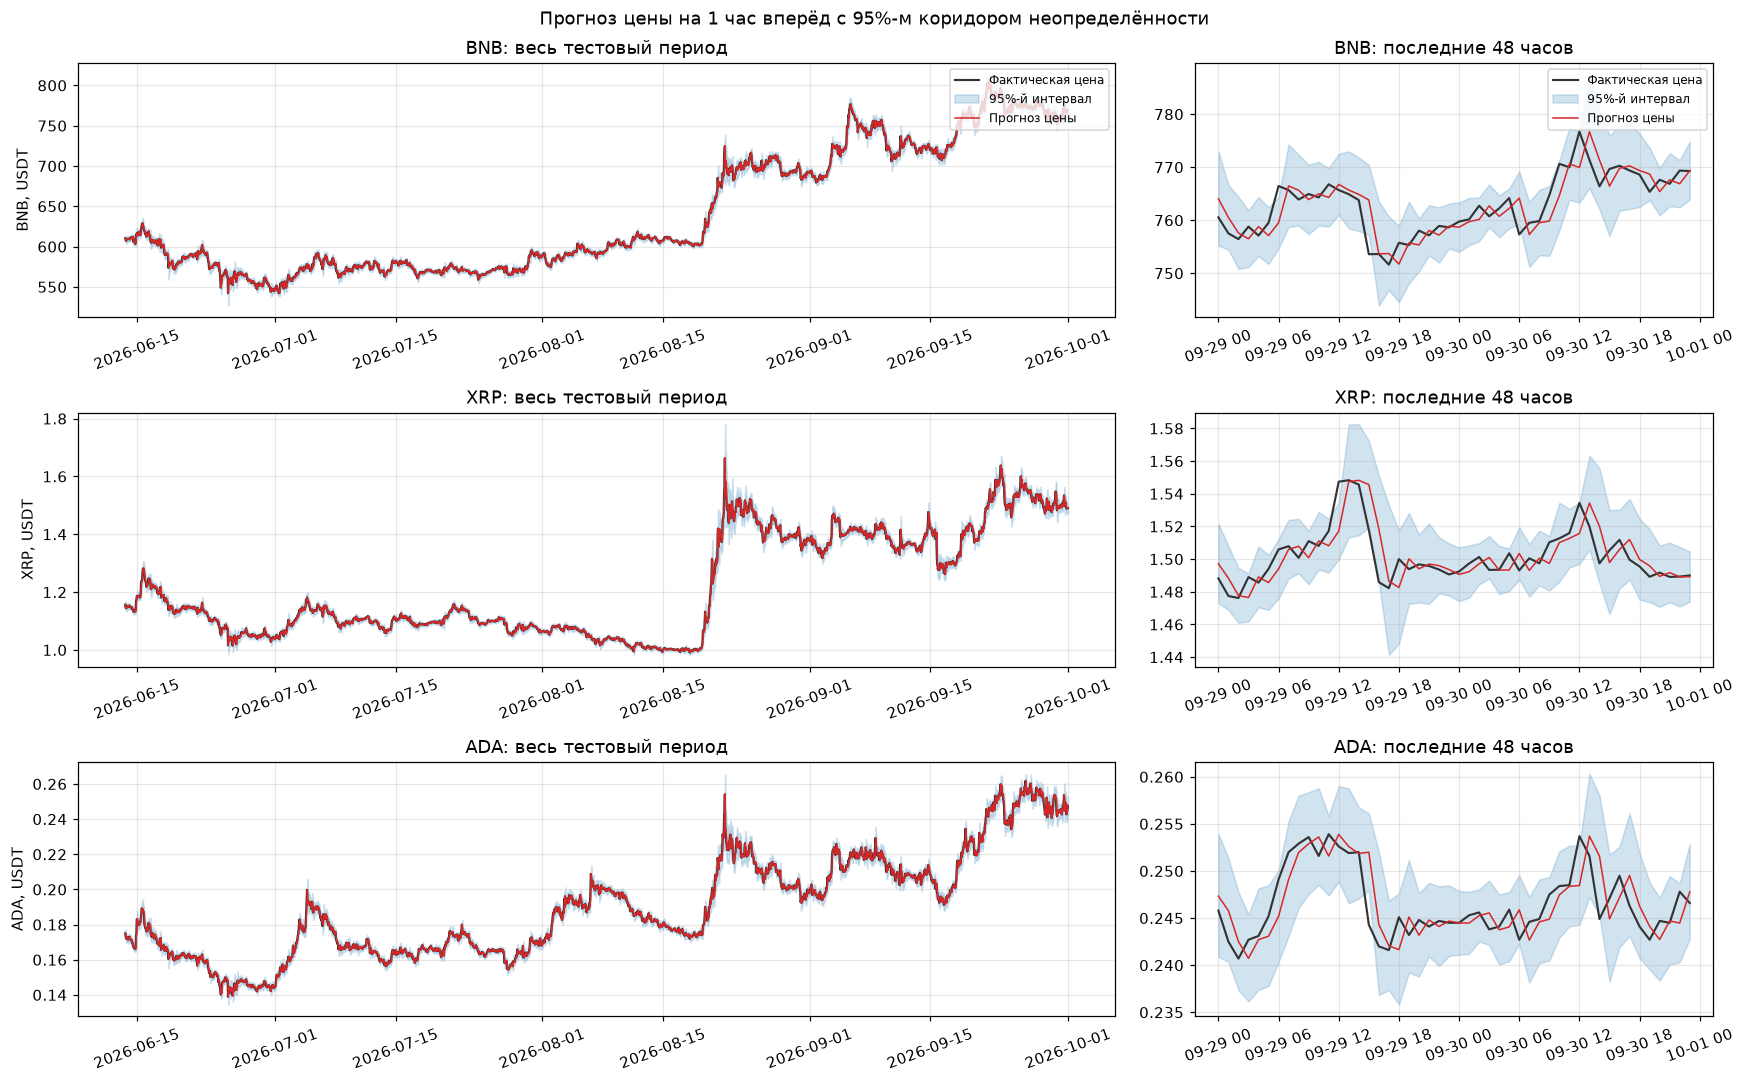

In [16]:

ZOOM_HOURS = 48


price_actual, price_prev, price_hat, price_lo, price_hi = {}, {}, {}, {}, {}

for asset in ASSETS:
    price_actual[asset] = prices[asset].reindex(test_index)
    price_prev[asset] = prices[asset].shift(1).reindex(test_index)


    price_hat[asset] = price_prev[asset] * np.exp(mean_pred_test[asset])


    price_lo[asset] = price_prev[asset] * np.exp(
        mean_pred_test[asset] - 1.96 * sigma[asset]
    )
    price_hi[asset] = price_prev[asset] * np.exp(
        mean_pred_test[asset] + 1.96 * sigma[asset]
    )


zoom_index_price = test_index[-ZOOM_HOURS:]

fig, axes = plt.subplots(
    3, 2,
    figsize=(16, 10),
    gridspec_kw={"width_ratios": [2, 1]}
)

for row, asset in enumerate(ASSETS):
    for col, idx in enumerate([test_index, zoom_index_price]):
        ax = axes[row, col]


        ax.plot(
            idx,
            price_actual[asset].loc[idx],
            lw=1.4,
            color="0.2",
            label="Фактическая цена"
        )


        ax.fill_between(
            idx,
            price_lo[asset].loc[idx],
            price_hi[asset].loc[idx],
            color="tab:blue",
            alpha=0.2,
            label="95%-й интервал"
        )


        ax.plot(
            idx,
            price_hat[asset].loc[idx],
            lw=1.0,
            color="tab:red",
            label="Прогноз цены"
        )

        ax.tick_params(axis="x", labelrotation=20)

    axes[row, 0].set_ylabel(f"{asset}, USDT")
    axes[row, 0].set_title(f"{asset}: весь тестовый период")
    axes[row, 1].set_title(f"{asset}: последние {ZOOM_HOURS} часов")

axes[0, 0].legend(loc="upper right", fontsize=8)
axes[0, 1].legend(loc="upper right", fontsize=8)

fig.suptitle("Прогноз цены на 1 час вперёд с 95%-м коридором неопределённости")
plt.tight_layout()
plt.show()

In [17]:

rows = []

for asset in ASSETS:

    err_model = price_actual[asset] - price_hat[asset]
    err_naive = price_actual[asset] - price_prev[asset]

    rows.append({
        "актив": asset,

        "MAE модели": err_model.abs().mean(),

        "RMSE модели": np.sqrt((err_model ** 2).mean())

    })

price_metrics = pd.DataFrame(rows).set_index("актив")

display(price_metrics.round(6))

,MAE модели,RMSE модели
актив,,
BNB,1.723434,2.608211
XRP,0.005362,0.009431
ADA,0.001129,0.001691
